Trabajamos sobre el **modelo final** de PI1: LightGBM con codificación **one-hot** y la configuración de
hiperparámetros hallada por **búsqueda aleatoria** (notebook 04, R²=0,902). Para la **importancia global**,
las columnas indicadoras de cada categórica (p. ej. `barrio`) se **agregan** a su variable de origen, de modo
que cada categórica se lea como una sola variable. Así, el modelo que se **explica** es exactamente el que se
**selecciona** en PI1.

## Metodología

- **Modelo:** LightGBM **one-hot** con la configuración final de búsqueda aleatoria (notebook 04),
  ajustado sobre todo el escenario S4. Es el mismo modelo seleccionado en PI1 (R²=0,902).
- **Explicador:** `TreeExplainer` (TreeSHAP, exacto para árboles) sobre la matriz transformada.
- **Importancia global:** se **agregan** las indicadoras one-hot a su variable de origen.
- **Lecturas:** importancia global (barras + *beeswarm*), **dependencias**, **explicaciones locales**
  (*waterfall*) y un **chequeo de coherencia** con la importancia por permutación del RF y los coeficientes
  del hedónico/Lasso.

> Nota: SHAP se calcula sobre el modelo ajustado en todo el dataset; su objeto es **explicar** el modelo,
> no medir su desempeño (eso se hizo con la CV en los notebooks previos).

In [1]:
from pathlib import Path
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import shap
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from lightgbm import LGBMRegressor

ROOT = Path.cwd()
while not (ROOT / "data" / "processed").exists() and ROOT != ROOT.parent: ROOT = ROOT.parent
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 130, "savefig.dpi": 130, "savefig.bbox": "tight", "font.size": 11})

df = pd.read_csv(ROOT / "data" / "processed" / "zonaprop_v2_matriz_modelado_centro.csv.gz")
y = np.log1p(pd.to_numeric(df["eda_precio_usd"], errors="coerce").values)
feat_cols = [c for c in df.columns if c.startswith("feat_")]
S1 = ["eda_superficie_total_m2","eda_superficie_cubierta_m2","eda_ambientes","eda_dormitorios",
      "eda_banos","eda_cocheras","eda_toilette","eda_antiguedad_anos","eda_antiguedad_estado",
      "eda_disposicion","eda_orientacion","eda_tipo_operacion","eda_expensas",
      "fe_ratio_cubierta_total","fe_sup_por_ambiente","fe_banos_por_ambiente",
      "fe_dormitorios_por_ambiente","fe_tiene_cochera","fe_expensas_informadas"]
S2 = ["barrio_oficial_geo","eda_latitud","eda_longitud"]
S3 = [c for c in ["fe_dist_centro_km","fe_dist_rio_km","fe_dist_espacio_verde_km","fe_dens_comercios_300m"] if c in df.columns]
S4 = [c for c in S1+S2+S3 if c in df.columns] + feat_cols
CAT = {"eda_antiguedad_estado","eda_disposicion","eda_orientacion","eda_tipo_operacion","barrio_oficial_geo"}
BIN = set(feat_cols) | {"fe_tiene_cochera","fe_expensas_informadas"}

def prep_oh(cols):
    cat=[c for c in cols if c in CAT]; binz=[c for c in cols if c in BIN]; num=[c for c in cols if c not in cat and c not in binz]
    return ColumnTransformer([
        ("cat", Pipeline([("i",SimpleImputer(strategy="most_frequent")),("o",OneHotEncoder(handle_unknown="ignore",min_frequency=10,sparse_output=False))]), cat),
        ("bin", SimpleImputer(strategy="most_frequent"), binz),
        ("num", SimpleImputer(strategy="median"), num)], remainder="drop")

# configuracion FINAL (one-hot, busqueda aleatoria) del notebook 04 -- R2=0.902
BP = dict(colsample_bytree=0.8604, learning_rate=0.0117, max_depth=10, min_child_samples=34,
          n_estimators=1105, num_leaves=16, reg_alpha=0.0061, reg_lambda=0.0061, subsample=0.7217)
final = Pipeline([("prep",prep_oh(S4)),("m",LGBMRegressor(random_state=42,n_jobs=-1,subsample_freq=1,verbose=-1,**BP))]).fit(df[S4], y)
names = [n.split("__",1)[-1] for n in final.named_steps["prep"].get_feature_names_out()]
Xt = pd.DataFrame(final.named_steps["prep"].transform(df[S4]), columns=names)
ex = shap.TreeExplainer(final.named_steps["m"])(Xt.values); ex.feature_names = names
print(f"SHAP (modelo final one-hot): {ex.values.shape[0]:,} casos x {ex.values.shape[1]} columnas - valor base = {float(ex.base_values[0]):.3f} (log) ~ USD {np.expm1(float(ex.base_values[0])):,.0f}")

REN = {"eda_superficie_total_m2":"Superficie total","eda_superficie_cubierta_m2":"Superficie cubierta",
 "eda_ambientes":"Ambientes","eda_dormitorios":"Dormitorios","eda_banos":"Baños","eda_cocheras":"Cocheras",
 "eda_toilette":"Toilette","eda_antiguedad_anos":"Antigüedad (años)","eda_antiguedad_estado":"Estado",
 "eda_disposicion":"Disposición","eda_orientacion":"Orientación","eda_tipo_operacion":"Tipo de operación",
 "eda_expensas":"Expensas","fe_ratio_cubierta_total":"Cubierta/total","fe_sup_por_ambiente":"Superficie por ambiente",
 "fe_banos_por_ambiente":"Baños por ambiente","fe_dormitorios_por_ambiente":"Dormitorios por ambiente",
 "fe_tiene_cochera":"Tiene cochera","fe_expensas_informadas":"Expensas informadas",
 "barrio_oficial_geo":"Barrio","eda_latitud":"Latitud","eda_longitud":"Longitud",
 "fe_dist_centro_km":"Distancia al centro (km)","fe_dist_rio_km":"Distancia al río (km)",
 "fe_dist_espacio_verde_km":"Distancia a espacio verde (km)","fe_dens_comercios_300m":"Densidad comercial (300 m)"}
REN.update({c: c.replace("feat_","").replace("_"," ").capitalize() for c in feat_cols})

# --- importancia global AGREGADA (one-hot -> variable de origen) ---
def orig(n):
    for c in CAT:
        if n.startswith(c+"_"): return c
    return n
mean_abs = np.abs(ex.values).mean(0)
agg = {}
for n,v in zip(names, mean_abs): agg[orig(n)] = agg.get(orig(n),0.0) + v
imp_glob = pd.Series(agg).sort_values(ascending=False); imp_glob.index=[REN.get(i,i) for i in imp_glob.index]
display(imp_glob.head(10).round(4).to_frame("SHAP medio |aporte|"))

ex.feature_names = [REN.get(n, n) for n in names]
Xt = Xt.rename(columns=REN)

# alias para las celdas siguientes
modelo = final.named_steps["m"]
X = Xt


SHAP (modelo final one-hot): 4,765 casos x 67 columnas - valor base = 11.672 (log) ~ USD 117,241


,SHAP medio |aporte|
Superficie total,0.3410
Antigüedad (años),0.1207
Baños,0.1047
Latitud,0.0472
Superficie cubierta,0.0451
Cochera,0.0324
Pileta,0.0312
Distancia al centro (km),0.0267
Balcon,0.0227
Amenities,0.0209


## 1. Importancia global

La media del valor absoluto de SHAP mide cuánto **mueve** cada variable el precio en el conjunto; el
*beeswarm* agrega la **dirección** (color = valor de la variable; posición = aporte al $\log$-precio).

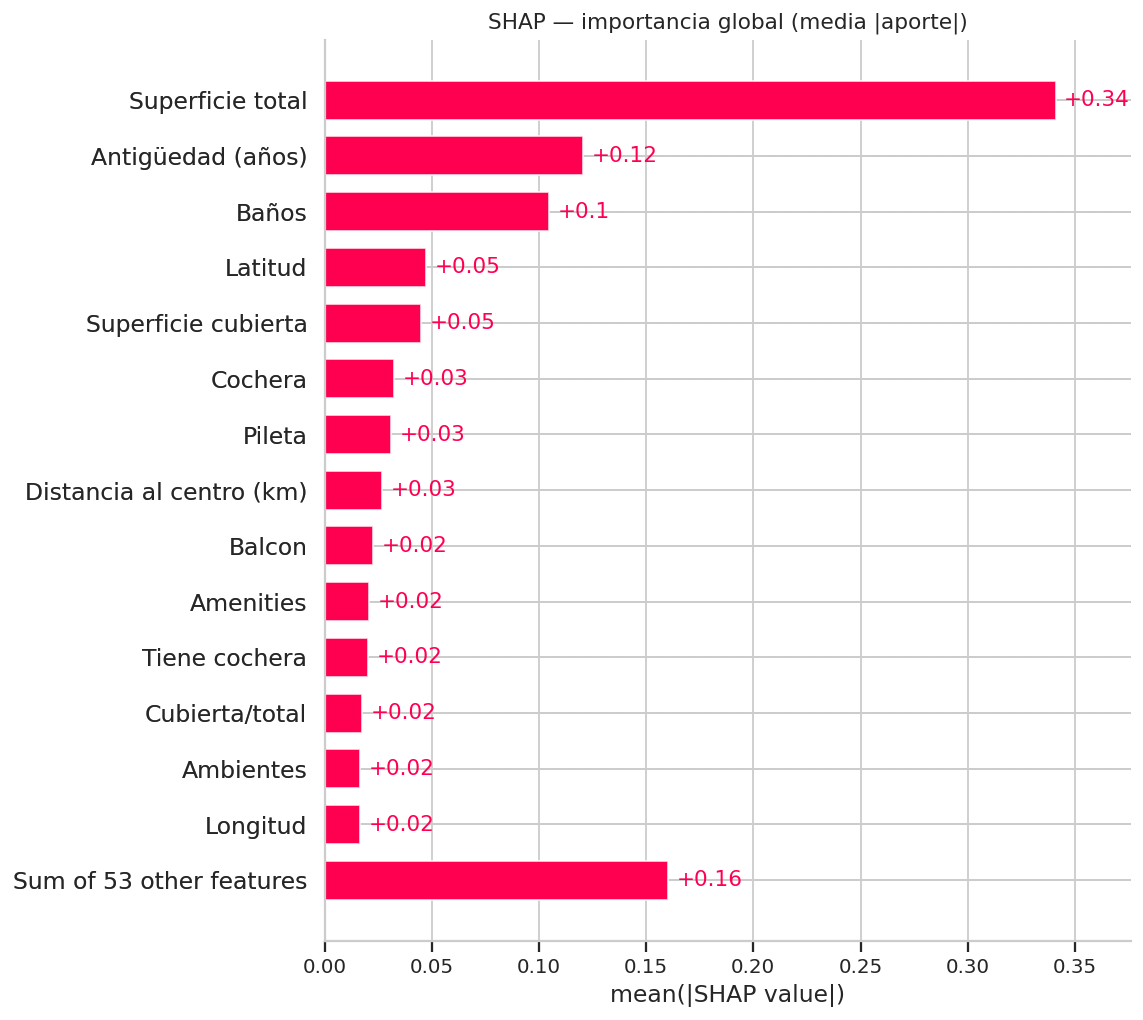

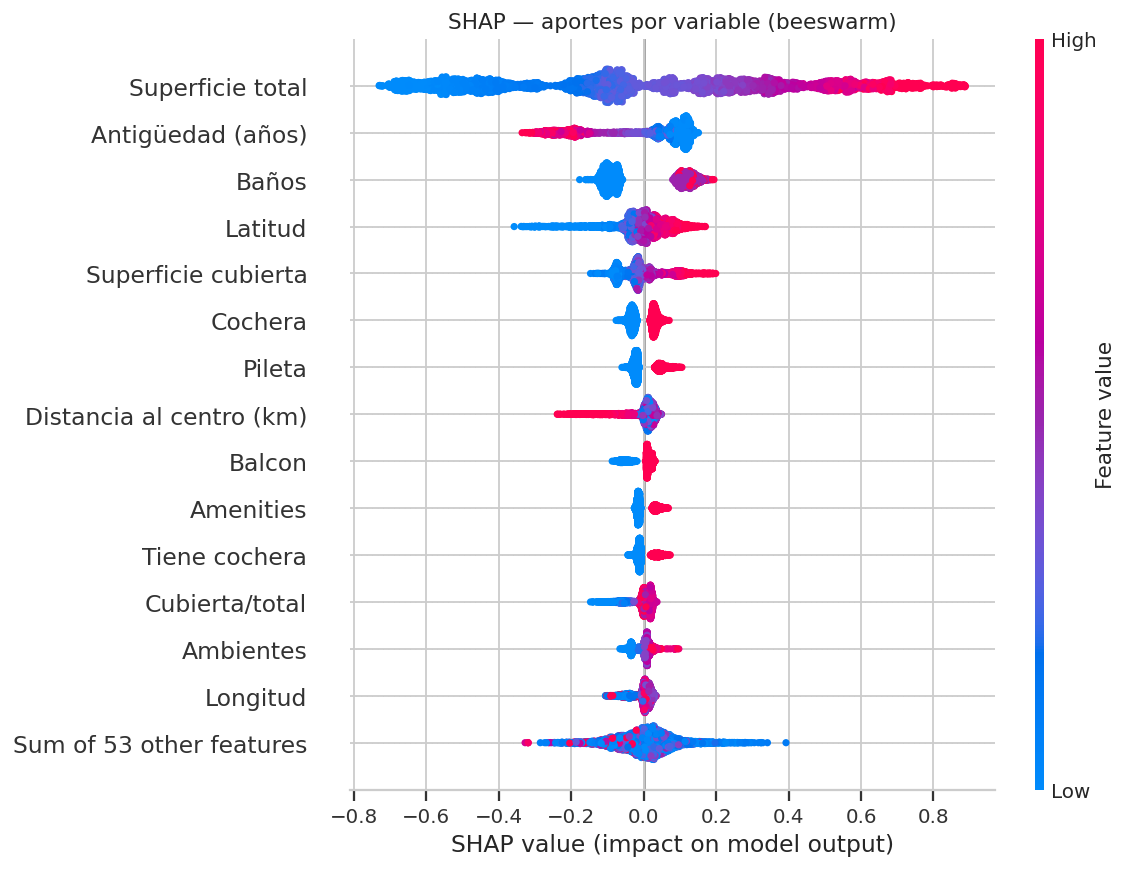

In [2]:
shap.plots.bar(ex, max_display=15, show=False); plt.title("SHAP — importancia global (media |aporte|)"); plt.show()
shap.plots.beeswarm(ex, max_display=15, show=False); plt.title("SHAP — aportes por variable (beeswarm)"); plt.show()

**Lectura.** La **superficie total** encabeza con amplitud (aporte medio ~0,29 en $\log$), seguida
por la **antigüedad** (~0,12), los **baños** (~0,10), la **superficie cubierta** (~0,08) y la **latitud**
(~0,04); `barrio` y algunos atributos de texto (cochera) aparecen más abajo. El *beeswarm* muestra los
signos esperables: los valores altos de superficie y de baños se ubican del lado de aportes **positivos**,
y la mayor antigüedad, del lado **negativo**. Es una jerarquía coherente con la de los modelos lineales.

## 2. Forma de los efectos (dependencias)

Cada punto es una propiedad: en el eje horizontal el valor de la variable, en el vertical su aporte SHAP.
La nube dibuja la **forma** del efecto (lineal, con saturación, con quiebres), que en el hedónico quedaba
impuesta como recta.

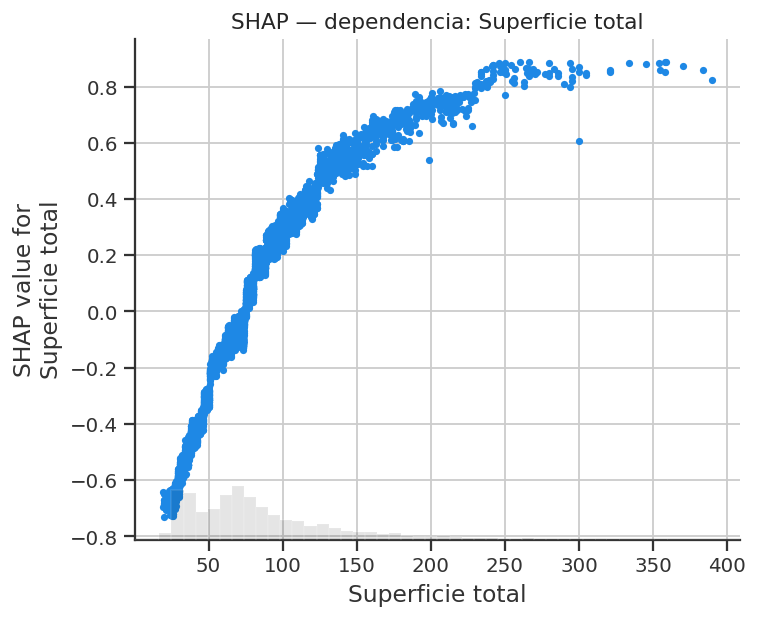

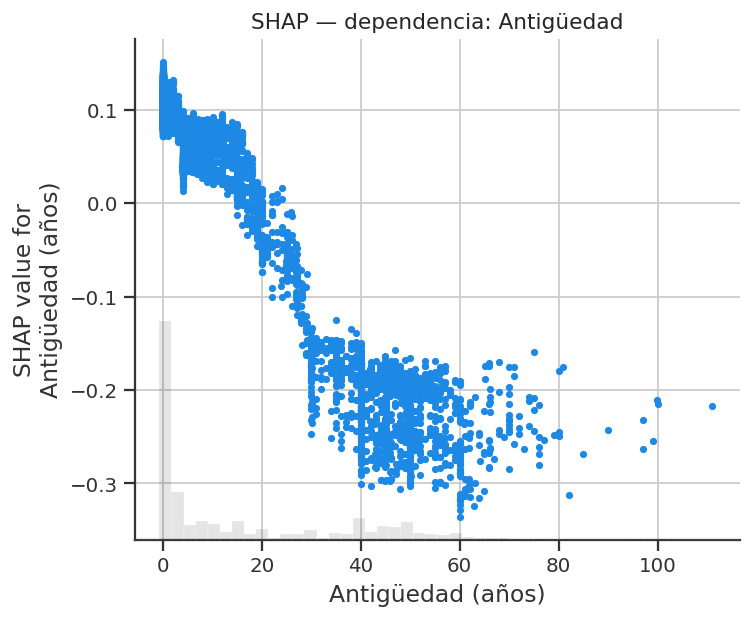

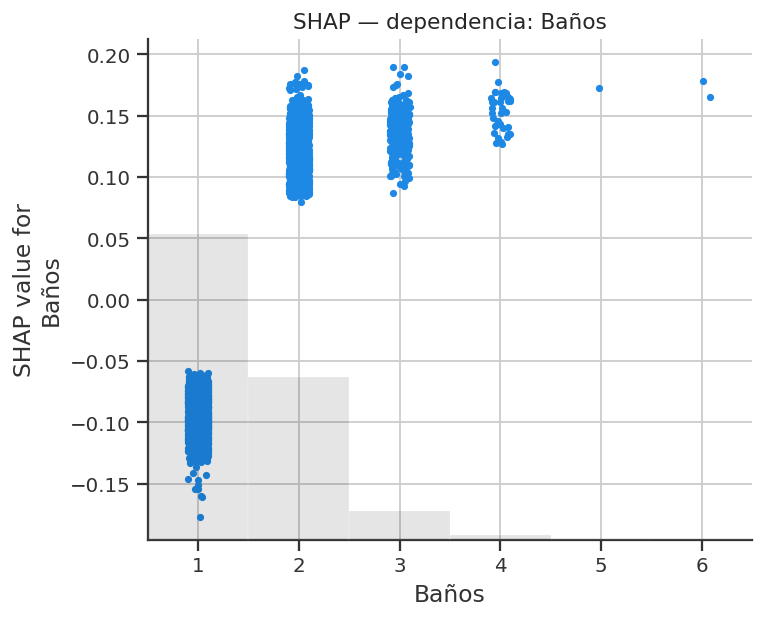

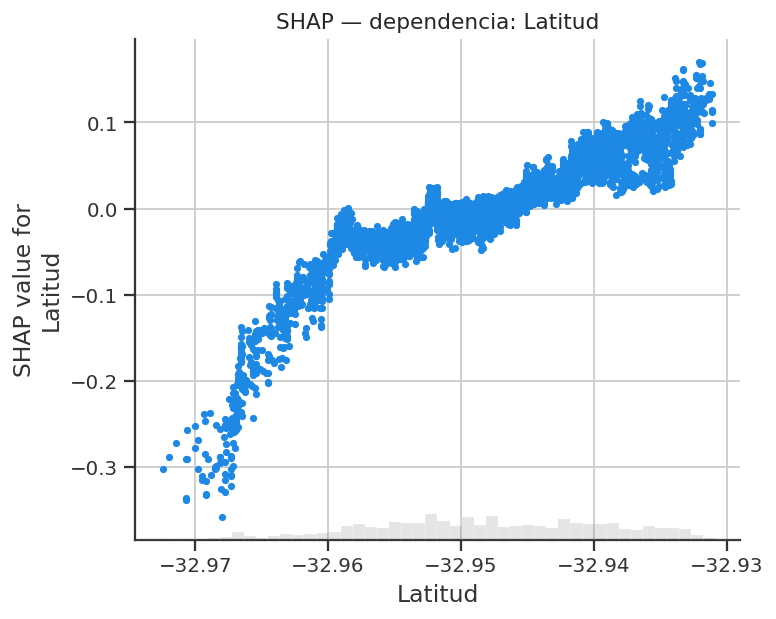

In [3]:
for var, titulo in [("Superficie total","Superficie total"),
                     ("Antigüedad (años)","Antigüedad"),
                     ("Baños","Baños"),
                     ("Latitud","Latitud")]:
    if var in X.columns:
        shap.plots.scatter(ex[:, var], show=False)
        plt.title(f"SHAP — dependencia: {titulo}"); plt.show()


**Lectura.** Las nubes describen efectos **no lineales**: en la **superficie**, el aporte crece y
tiende a **aplanarse** en los valores altos (saturación, compatible con la elasticidad < 1 estimada en el
hedónico); en la **antigüedad**, el aporte es **decreciente**; en **baños** se observan saltos discretos;
y la **latitud** dibuja un patrón asociado a la geografía del distrito. Estas formas —que el hedónico
imponía como rectas— son parte de lo que explicaría la ventaja del modelo flexible, ahora de manera
interpretable.

## 3. Explicaciones locales: cómo se arma cada tasación

El gráfico *waterfall* descompone la predicción de **un** inmueble: parte del **valor base** (el
$\log$-precio promedio) y suma/resta el aporte de cada variable hasta la predicción final. Mostramos tres
casos —de precio **bajo**, **medio** y **alto**— para ilustrar la lectura individual.

Caso bajo: precio observado $49,000 · predicho $51,861


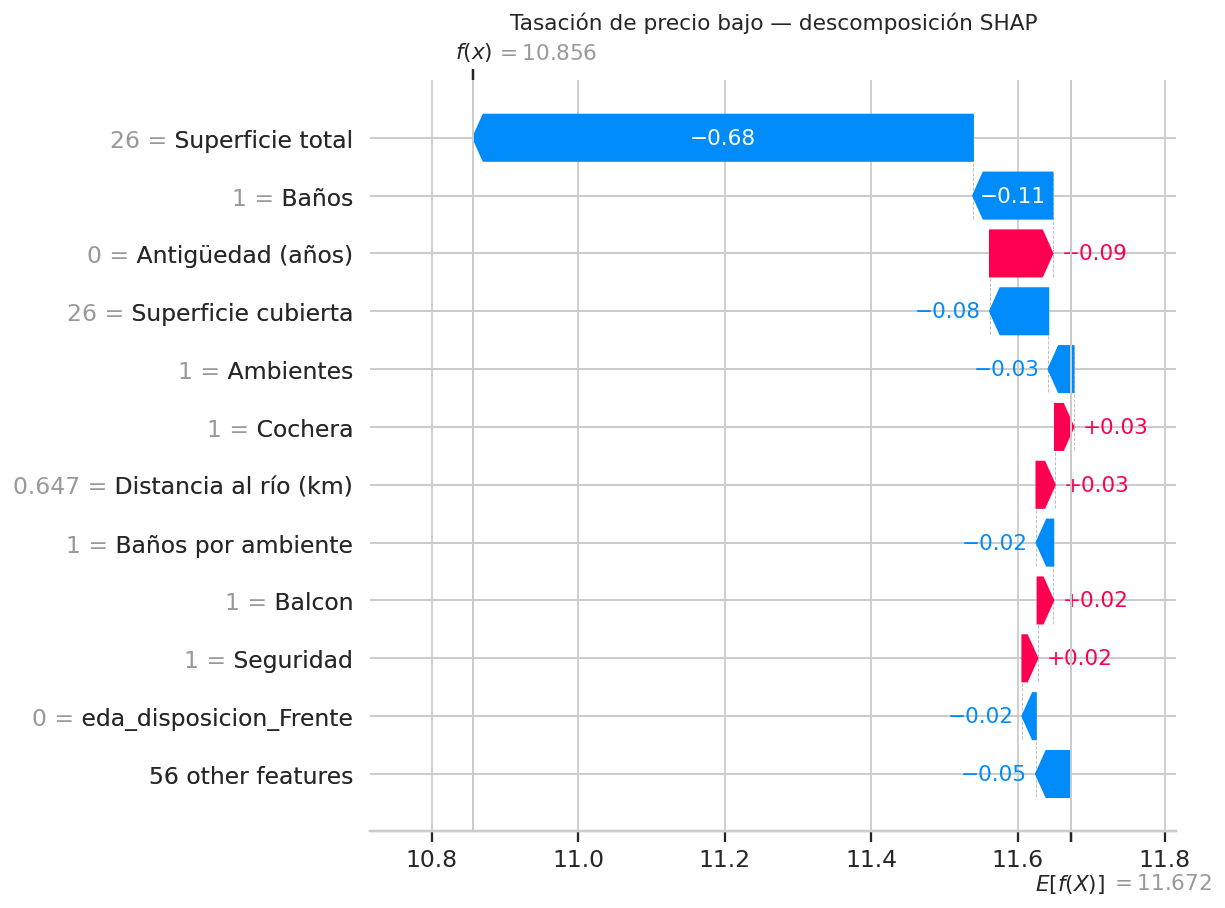

Caso medio: precio observado $117,000 · predicho $120,402


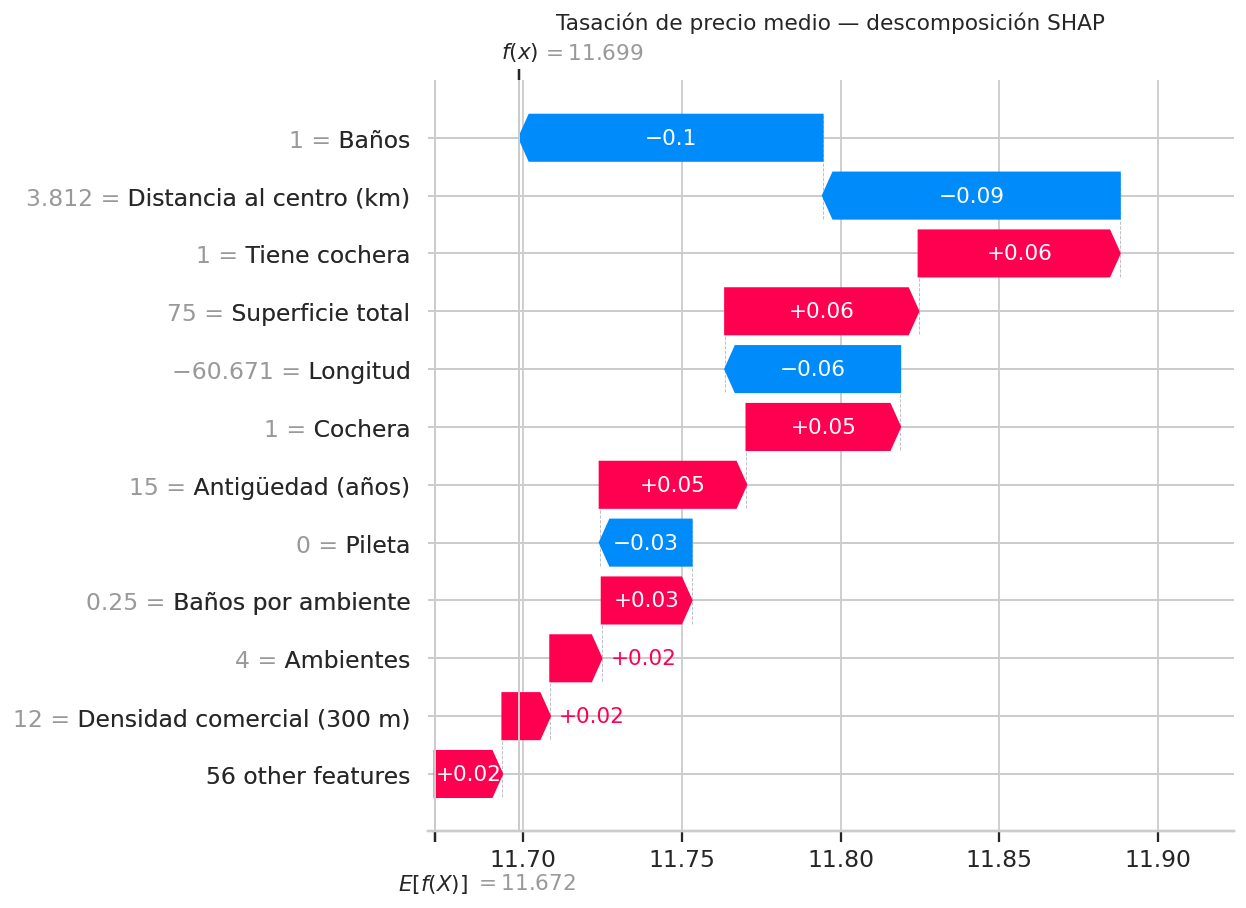

Caso alto: precio observado $300,000 · predicho $242,627


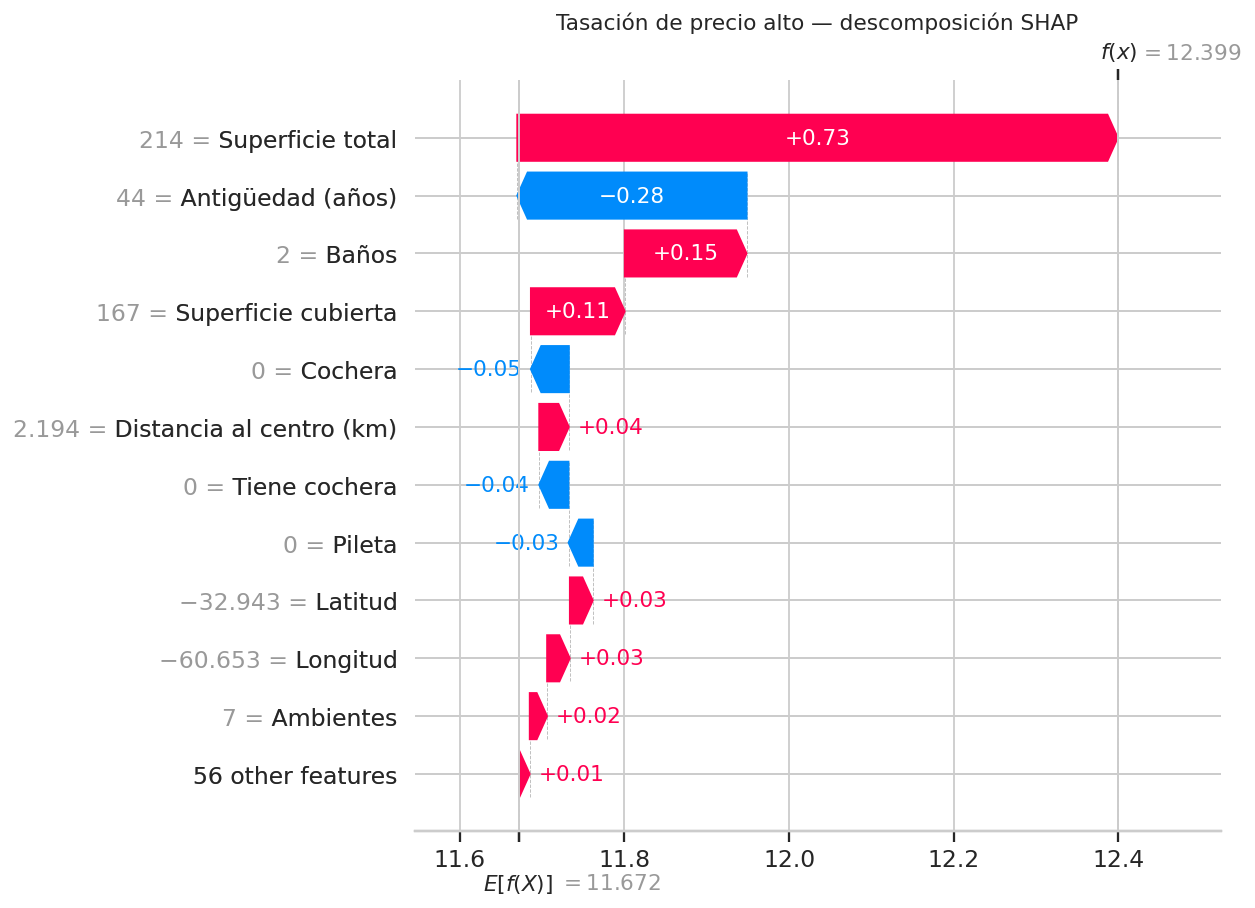

In [4]:
ytu = np.expm1(y)
casos = {"bajo": int(np.argsort(ytu)[int(0.10*len(ytu))]),
         "medio": int(np.argsort(ytu)[int(0.50*len(ytu))]),
         "alto": int(np.argsort(ytu)[int(0.90*len(ytu))])}
for etiqueta, i in casos.items():
    print(f"Caso {etiqueta}: precio observado ${ytu[i]:,.0f} · predicho ${np.expm1(modelo.predict(X.iloc[[i]]))[0]:,.0f}")
    shap.plots.waterfall(ex[i], max_display=12, show=False)
    plt.title(f"Tasación de precio {etiqueta} — descomposición SHAP"); plt.show()

**Lectura.** Los tres *waterfall* reconstruyen la tasación caso por caso desde el **valor base**
(~$\log$ 11,67, es decir ~USD 117k). En el caso **medio**, la predicción queda muy cerca del observado
(~USD 116k vs. USD 117k). En el **alto** (USD 300k observado), el modelo **subestima** (~USD 232k), en
línea con la mayor dificultad de la cola cara que ya mostraba el análisis por segmento (pocas propiedades,
muy heterogéneas). En cada gráfico puede leerse qué atributos **empujan hacia arriba** (superficie amplia,
varios baños, ubicación) y cuáles **hacia abajo** (antigüedad, superficie chica). Es la evidencia más
directa de la **explicabilidad**: para cualquier inmueble se puede mostrar el porqué de su valuación.

## 4. Coherencia con los otros métodos

Comparamos el orden global de SHAP con la **importancia por permutación** del Random Forest (notebook 03),
sobre las variables numéricas compartidas. La coincidencia entre enfoques distintos aportaría respaldo a
la lectura sustantiva.

In [5]:
sh = imp_glob.copy()                      # importancia SHAP global agregada (one-hot -> variable)
sh_rank = {v:i+1 for i,v in enumerate(sh.index)}
rf_path = ROOT/"reports"/"tables"/"modelado"/"random_forest_importancias_s4.csv"
filas=[]
if rf_path.exists():
    rf = pd.read_csv(rf_path).sort_values("importancia_perm", ascending=False).reset_index(drop=True)
    rf["feature"] = rf["feature"].map(lambda n: REN.get(n, n))
    rf_rank = {r.feature:i+1 for i,r in rf.iterrows()}
    comunes = [v for v in sh.index if v in rf_rank][:10]
    for v in comunes:
        filas.append({"variable":v, "rank_SHAP":sh_rank[v], "rank_RF_perm":rf_rank.get(v, np.nan),
                      "SHAP_medio":round(float(sh[v]),4)})
    display(pd.DataFrame(filas).set_index("variable"))
else:
    display(sh.head(10).round(4).to_frame("SHAP_medio"))


,rank_SHAP,rank_RF_perm,SHAP_medio
variable,,,
Superficie total,1,1,0.3410
Antigüedad (años),2,3,0.1207
Baños,3,4,0.1047
Latitud,4,6,0.0472
Superficie cubierta,5,2,0.0451
Cochera,6,8,0.0324
Pileta,7,9,0.0312
Distancia al centro (km),8,11,0.0267
Balcon,9,22,0.0227


**Lectura.** El orden global de SHAP (con las categóricas agregadas) y el de la importancia por permutación
del RF muestran una **convergencia cualitativa**: cuatro de las cinco principales de SHAP están entre las
cinco primeras del RF por permutación; la latitud, cuarta según SHAP, aparece sexta por permutación. Son
enfoques que **no miden exactamente el mismo objeto** —SHAP explica un LightGBM, la permutación mide caída de
desempeño en el RF, y el hedónico/Lasso usan coeficientes—, pero apuntan a los mismos predictores dominantes
(superficie, antigüedad, baños y localización), lo que aporta respaldo convergente a la lectura sustantiva.

## 5. Conclusiones (RQ5)

- **Lectura global.** SHAP recupera, para el modelo flexible, una jerarquía interpretable (superficie,
  antigüedad, baños, superficie cubierta, ambientes y localización) **coherente** con OLS, Lasso y la
  importancia por permutación del RF.
- **Forma de los efectos.** Las dependencias hacen explícitas las **no linealidades** (saturación de la
  superficie, efecto de la antigüedad) que el hedónico imponía como rectas — una ventaja del ML que aquí
  se vuelve **interpretable**.
- **Explicaciones locales.** El *waterfall* justifica **cada** tasación individual; el caso de precio alto
  ilustra además la **subestimación en la cola cara**, una limitación ya diagnosticada por segmento.
- **Cierre.** Con la interpretabilidad (RQ5) queda cubierto el conjunto de preguntas de investigación; el
  material de este notebook, junto con el diagnóstico espacial y la comparación de modelos, alimenta la
  discusión final.

## Referencias

**Libros**

- Molnar, C. (2022). *Interpretable Machine Learning* (2ª ed.). — valores de Shapley, SHAP, dependencias y explicaciones locales.

**Artículos**

- Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions (SHAP). *NeurIPS 30*.
- Lundberg, S. M., et al. (2020). From local explanations to global understanding with explainable AI for trees (TreeSHAP). *Nature Machine Intelligence, 2*, 56–67.
- Gyger et al. (2026). Explainable spatial machine learning for hedonic real estate modeling. *Real Estate Economics*.